# 04 · Substitution Severity Score (SSS)

SSS(i → j) = [ EVOscore(i → j) + DI(i, j) ] / 2, with both terms scaled to 0–1.

- **EVOscore** = −log10(f_variant / f_wildtype) from the ConSurf multiple-sequence alignment of GAA
- **DI** = physicochemical distance between the two amino acids, from 544 AAindex properties (SeqinR)

No EVE information enters the SSS (the earlier benchmark used an EVE-based score).

In [1]:
%matplotlib inline
import sys, json, inspect, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from gaa_hotspot import data, network, stats, ml, figures as F
from gaa_hotspot import sss as sss_mod
from gaa_hotspot.common import AA, MODEL_ORDER, MODEL_NAMES, config, raw, read_processed, table, load_values
from gaa_hotspot.plotting import apply_style, MODEL_COLOURS, MODEL_LABELS, MODEL_SHORT, V7_MODEL_ORDER

apply_style()
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
cfg = config()
V = load_values()
print("project root:", ROOT)

project root: Pompe-GAA-Hotspots


## 1. ConSurf alignment frequencies

The ConSurf grades file lists, for every position, the residue variety observed in the alignment:

In [2]:
lines = raw("conservation", "5NN3_consurf_grades.txt").read_text().splitlines()
print(*[l[:175] for l in lines[:20]], sep="\n")

	
 POS	 SEQ	       ATOM	 SCORE	COLOR	CONFIDENCE INTERVAL	B/E	F/S	MSA DATA	RESIDUE VARIETY

  1	  Q	 GLN:81:AAA	-0.867	   8 	-1.086, -0.711  9,7	  e	  f	  26/300	Q 73%, K 19%, R  3%, C  3%
  2	  C	 CYS:82:AAA	-1.173	   9 	-1.346, -1.086  9,9	  e	  f	  39/300	C
  3	  D	 ASP:83:AAA	 1.084	   3 	 0.499,  1.444  4,2	  e	   	  79/300	N 27%, D 20%, S 12%, E 11%, V  7%, T  3%, I  3%, A  2%, Q  2%, G  2%, H  1%, P  1%, L  1%, C  1%
  4	  V	 VAL:84:AAA	 0.609	   4 	 0.180,  0.717  5,4	  e	   	 107/300	I 43%, V 28%, L  8%, T  6%, M  4%, D  2%, F  1%, R <1%, P <1%, E <1%, S <1%
  5	  P	 PRO:85:AAA	 0.457	   4 	 0.056,  0.717  5,4	  e	   	 118/300	P 69%, A 10%, D  4%, N  4%, S  2%, E  1%, L  1%, T  1%, Q  1%, H <1%, R <1%, K <1%
  6	  P	 PRO:86:AAA	 0.665	   4 	 0.327,  1.004  4,3	  e	   	 134/300	E 35%, P 20%, D 12%, V  8%, L  6%, I  5%, A  2%, N  2%, T  2%, Q  1%, S <1%, K <1%, R <1%
  7	  N	 ASN:87:AAA	 1.379	   3 	 1.004,  1.444  3,2	  e	   	 162/300	N 23%, S 20%, A 16%, E 10%, D  8%, G  3%, T 

In [3]:
freq = data.consurf_frequencies()      # positions x 20 amino-acid frequencies
print(freq.shape)
freq.head()

(847, 21)


,wt_consurf,A,R,N,D,C,Q,E,G,H,I,L,K,M,F,P,S,T,W,Y,V
residue,,,,,,,,,,,,,,,,,,,,,
81,Q,0.00,0.030,0.00,0.00,0.03,0.73,0.000,0.00,0.000,0.00,0.00,0.190,0.00,0.00,0.000,0.000,0.00,0.0,0.0,0.00
82,C,0.00,0.000,0.00,0.00,1.00,0.00,0.000,0.00,0.000,0.00,0.00,0.000,0.00,0.00,0.000,0.000,0.00,0.0,0.0,0.00
83,D,0.02,0.000,0.27,0.20,0.01,0.02,0.110,0.02,0.010,0.03,0.01,0.000,0.00,0.00,0.010,0.120,0.03,0.0,0.0,0.07
84,V,0.00,0.005,0.00,0.02,0.00,0.00,0.005,0.00,0.000,0.43,0.08,0.000,0.04,0.01,0.005,0.005,0.06,0.0,0.0,0.28
85,P,0.10,0.005,0.04,0.04,0.00,0.01,0.010,0.00,0.005,0.00,0.01,0.005,0.00,0.00,0.690,0.020,0.01,0.0,0.0,0.00


In [4]:
seq = read_processed("residue_features.csv").set_index("residue")["wt"]     # the 844 RIN residues
common = freq.index.intersection(seq.index)
print("positions in ConSurf:", len(freq), "  residues in the RIN:", len(seq), "  shared:", len(common))
print("wild-type mismatches between alignment and structure:", int((freq.loc[common, "wt_consurf"] != seq[common]).sum()))
print("\nexample, catalytic nucleophile D518:", {k: v for k, v in freq.loc[518, AA].items() if v > 0})

positions in ConSurf: 847   residues in the RIN: 844   shared: 844
wild-type mismatches between alignment and structure: 0

example, catalytic nucleophile D518: {'D': 0.95, 'E': 0.03, 'G': 0.005, 'V': 0.005}


## 2. EVOscore, step by step for D518

Amino acids never observed at a position get f = 0.001 (0.1%); `<1%` entries are taken as 0.5%. EVOscore is clipped to [0, 3] (3 = −log10(0.001)) and divided by 3.

In [5]:
floor, cap = cfg["sss"]["min_frequency"], cfg["sss"]["evoscore_cap"]
p, w = 518, seq[518]
f = freq.loc[p, AA].astype(float).clip(lower=floor)
evo = -np.log10(f / f[w])
pd.DataFrame({"f (alignment)": freq.loc[p, AA], "f used": f, "EVOscore": evo, "EVOscore scaled": evo.clip(0, cap) / cap}).T.round(3)

,A,R,N,D,C,Q,E,G,H,I,L,K,M,F,P,S,T,W,Y,V
f (alignment),0.0,0.0,0.0,0.95,0.0,0.0,0.03,0.005,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.005
f used,0.001,0.001,0.001,0.95,0.001,0.001,0.03,0.005,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.005
EVOscore,2.9777,2.9777,2.9777,-0.0,2.9777,2.9777,1.5006,2.2788,2.9777,2.9777,2.9777,2.9777,2.9777,2.9777,2.9777,2.9777,2.9777,2.9777,2.9777,2.2788
EVOscore scaled,0.9926,0.9926,0.9926,-0.0,0.9926,0.9926,0.5002,0.7596,0.9926,0.9926,0.9926,0.9926,0.9926,0.9926,0.9926,0.9926,0.9926,0.9926,0.9926,0.7596


In [6]:
evo_all = sss_mod.evoscore(freq.loc[common], seq[common], floor)
vals = evo_all.values[~np.isclose(evo_all.values, 0)]
print(f"EVOscore over all substitutions: min {vals.min():.2f}, median {np.median(vals):.2f}, max {vals.max():.2f}")
print(f"fraction negative (variant more frequent than wild type): {(vals < 0).mean():.3f};  fraction at the cap: {(vals >= cap).mean():.3f}")

EVOscore over all substitutions: min -1.94, median 1.97, max 3.00
fraction negative (variant more frequent than wild type): 0.059;  fraction at the cap: 0.004


## 3. Physicochemical distance index (DI)

544 AAindex properties exported from SeqinR (`scripts/00_export_aaindex.R`):

In [7]:
ai = pd.read_csv(raw("physicochemical", "aaindex1_seqinr.csv"))
print(ai.shape)
display(ai.head())
props = ai[AA]
print("properties with a missing value:", int(props.isna().any(axis=1).sum()), "-> filled with that property's mean")
props = props.apply(lambda r: r.fillna(r.mean()), axis=1)

(544, 22)


,index_id,description,A,R,N,D,C,Q,E,G,H,I,L,K,M,F,P,S,T,W,Y,V
0,ANDN920101,"alpha-CH chemical shifts (Andersen et al., 1992)",4.35,4.38,4.75,4.76,4.65,4.37,4.29,3.97,4.63,3.95,4.17,4.36,4.52,4.66,4.44,4.50,4.35,4.70,4.60,3.95
1,ARGP820101,"Hydrophobicity index (Argos et al., 1982)",0.61,0.60,0.06,0.46,1.07,0.00,0.47,0.07,0.61,2.22,1.53,1.15,1.18,2.02,1.95,0.05,0.05,2.65,1.88,1.32
2,ARGP820102,Signal sequence helical potential (Argos et al...,1.18,0.20,0.23,0.05,1.89,0.72,0.11,0.49,0.31,1.45,3.23,0.06,2.67,1.96,0.76,0.97,0.84,0.77,0.39,1.08
3,ARGP820103,Membrane-buried preference parameters (Argos e...,1.56,0.45,0.27,0.14,1.23,0.51,0.23,0.62,0.29,1.67,2.93,0.15,2.96,2.03,0.76,0.81,0.91,1.08,0.68,1.14
4,BEGF750101,Conformational parameter of inner helix (Beghi...,1.00,0.52,0.35,0.44,0.06,0.44,0.73,0.35,0.60,0.73,1.00,0.60,1.00,0.60,0.06,0.35,0.44,0.73,0.44,0.82


properties with a missing value: 13 -> filled with that property's mean


Standardise each property across the 20 amino acids, then PCA:

components needed for >= 99% variance: 18 (99.39%)


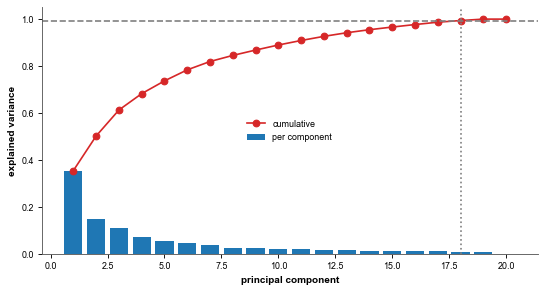

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
z = StandardScaler().fit_transform(props.T.values)     # 20 amino acids x 544 properties
pca = PCA().fit(z)
cum = np.cumsum(pca.explained_variance_ratio_)
k = int(np.searchsorted(cum, cfg["sss"]["pca_variance"]) + 1)
print(f"components needed for >= 99% variance: {k} ({100 * cum[k - 1]:.2f}%)")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color="#1f77b4", label="per component")
ax.plot(range(1, len(cum) + 1), cum, "o-", color="#d62728", label="cumulative")
ax.axhline(0.99, ls="--", color="grey"); ax.axvline(k, ls=":", color="grey")
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance"); ax.legend(); plt.show()

In [9]:
from scipy.spatial.distance import pdist, squareform
di = pd.DataFrame(squareform(pdist(pca.transform(z)[:, :k])), index=AA, columns=AA)
di_lib, info = sss_mod.distance_index(cfg["sss"]["pca_variance"])
print("identical to the pipeline:", np.allclose(di, di_lib)); print(info)
legacy = pd.read_csv(raw("physicochemical", "legacy_DI_matrix.csv")).dropna(subset=["Reference_aa"])
L = legacy.pivot(index="Reference_aa", columns="Variety_aa", values="Physiochem_score").loc[AA, AA]
iu = np.triu_indices(20, 1)
print(f"Pearson r with the DI matrix used in earlier drafts: {np.corrcoef(di.values[iu], L.values[iu])[0, 1]:.4f}")

identical to the pipeline: True
{'n_properties': 544, 'n_properties_imputed': 13, 'n_components': 18, 'variance_retained': 0.9938838955590905, 'di_max': 48.944860999779706}
Pearson r with the DI matrix used in earlier drafts: 0.9923


### Supplementary Figure S8 — DI matrix and EVOscore distribution

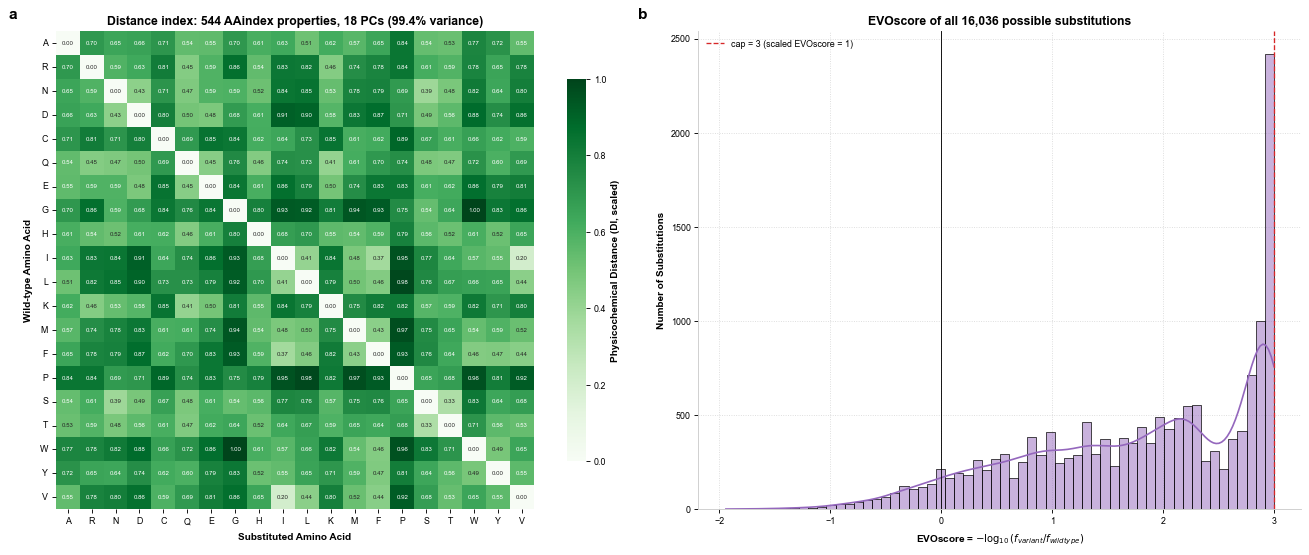

In [10]:
sss = sss_mod.severity_long(freq, seq[common], di, floor, cap)
title = f"Distance index: {info['n_properties']} AAindex properties, {k} PCs ({100 * cum[k - 1]:.1f}% variance)"
F.figS_di_evoscore(di, sss, cap, title)
plt.show()

## 4. SSS for every possible substitution

In [11]:
stored = read_processed("sss_all_substitutions.csv")
print(len(sss), "substitutions at", sss.residue.nunique(), "residues; identical to stored file:", np.allclose(sss.sss.values, stored.sss.values))
assert np.allclose(sss.sss, (sss.evoscore_scaled + sss.di_scaled) / 2)
sss.head()

16036 substitutions at 844 residues; identical to stored file: True


,residue,wt,mt,variant,f_wt,f_mt,evoscore,evoscore_scaled,di,di_scaled,sss
0,81,Q,A,Q81A,0.73,0.00,2.8633,0.9544,26.6306,0.5441,0.7493
1,81,Q,R,Q81R,0.73,0.03,1.3862,0.4621,22.2658,0.4549,0.4585
2,81,Q,N,Q81N,0.73,0.00,2.8633,0.9544,22.9436,0.4688,0.7116
3,81,Q,D,Q81D,0.73,0.00,2.8633,0.9544,24.4205,0.4989,0.7267
4,81,Q,C,Q81C,0.73,0.03,1.3862,0.4621,33.9829,0.6943,0.5782


In [12]:
cls = np.select([sss.sss < 0.5, sss.sss <= 0.6], ["Benign (< 0.5)", "Unknown (0.5-0.6)"], "Severe (> 0.6)")
print(pd.Series(cls).value_counts().to_string())
print("\nmost severe substitutions:")
sss.sort_values("sss", ascending=False).head(15)[["variant", "f_wt", "f_mt", "evoscore", "di", "sss"]]

Severe (> 0.6)       9620
Benign (< 0.5)       4362
Unknown (0.5-0.6)    2054

most severe substitutions:


,variant,f_wt,f_mt,evoscore,di,sss
16005,W951G,1.00,0.0,3.0000,48.9449,1.0000
4576,G335W,0.99,0.0,2.9956,48.9449,0.9993
14209,G855W,0.99,0.0,2.9956,48.9449,0.9993
10761,W661G,0.99,0.0,2.9956,48.9449,0.9993
4747,G344W,0.99,0.0,2.9956,48.9449,0.9993
3132,G259W,0.99,0.0,2.9956,48.9449,0.9993
10428,G643W,0.99,0.0,2.9956,48.9449,0.9993
5241,G370W,0.99,0.0,2.9956,48.9449,0.9993
4557,G334W,0.99,0.0,2.9956,48.9449,0.9993
10523,G648W,0.99,0.0,2.9956,48.9449,0.9993


### Figure 5a — SSS framework (DI matrix shown, not BLOSUM62)

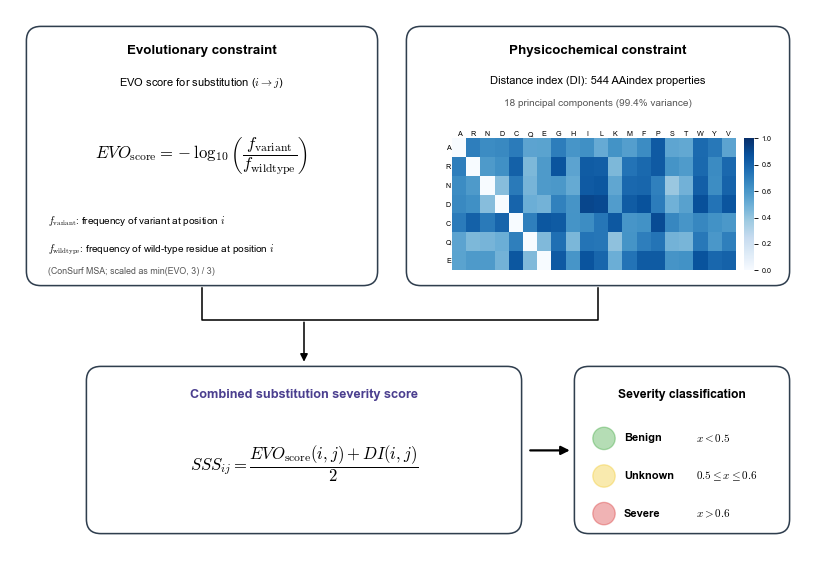

In [13]:
F.fig5a_schematic(di, info["n_properties"], k, cum[k - 1])
plt.show()

### Figure 5b — SSS at the novel consensus hotspots

Grey cells = wild-type residue.

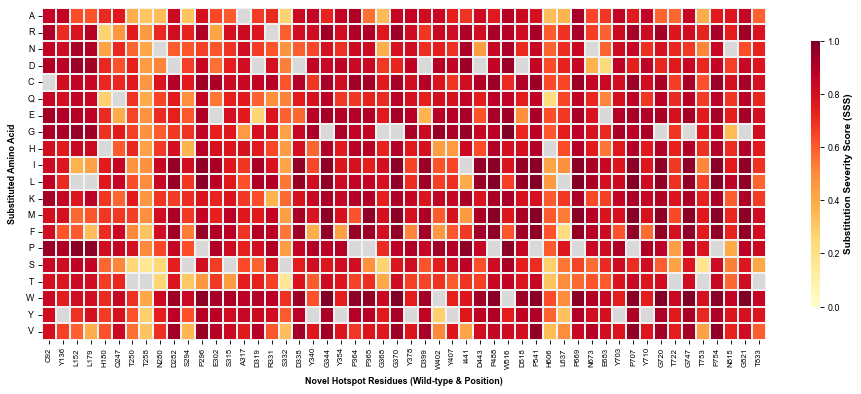

mean SSS at novel hotspots 0.759 vs all other residues 0.630


In [14]:
novel = pd.read_csv(table("novel_hotspots.csv")).set_index("residue")
feat = read_processed("residue_features.csv").set_index("residue")
F.fig5b_novel_heatmap(sss, novel, feat)
plt.show()
mean_novel = sss[sss.residue.isin(novel.index)].groupby("residue").sss.mean()
print(f"mean SSS at novel hotspots {mean_novel.mean():.3f} vs all other residues {sss[~sss.residue.isin(novel.index)].groupby('residue').sss.mean().mean():.3f}")

### Supplementary Figure S9 — SSS across the whole protein

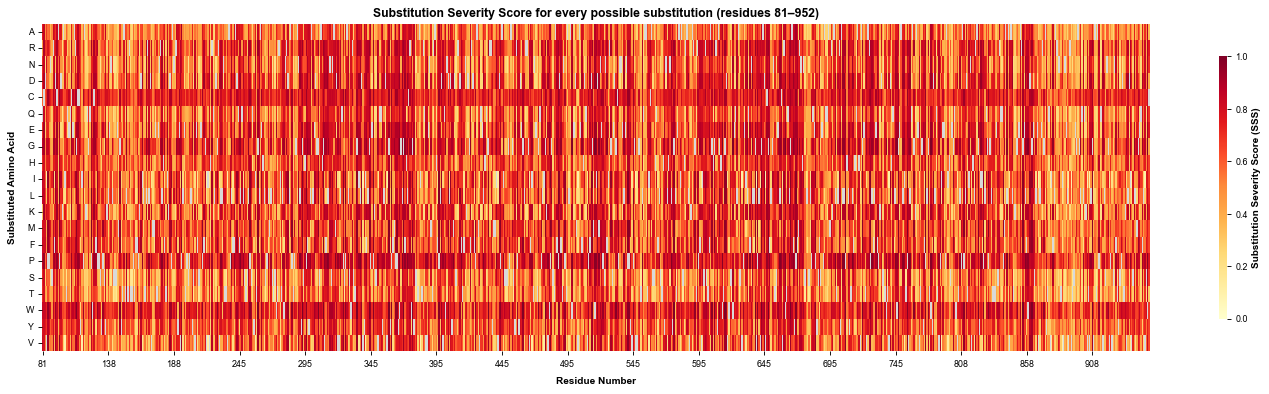

In [15]:
F.figS_full_protein_sss(sss)
plt.show()